# Notebook 1: Optical Audit & Calibrated Greater Cumberland Plateau Baseline

This notebook documents the methodological audit and full bug-fix rebuild of the
Greater Cumberland Plateau optical study:
1. Quantifying the Landsat Collection 2 inter-sensor winter step-jump (`L5 -> L7 -> L8/9`,
   LEDAPS vs. LaSRC) and its 79% collapse of apparent 40-year "mesophication".
2. Attributing the residual single-sensor Landsat 5 (1985-2011) deciduous winter slope
   using Annual NLCD stand-age cohorts, Daymet V4 winter climate, and SWIR indices (NBR/NDMI).
3. Rebuilding all 8 Tennessee comparison units with the complete Fall Creek Falls State Park
   boundary (10,282 ha, replacing the truncated 2,946 ha WDPA WMA sub-unit), consistent
   `>= 430 m` plateau-top masking, Annual NLCD Collection 1.0 (1985-2024), and corrected
   `km^2` loss units (fixing the v1 100x `ha` vs. `km^2` display bug).

In [1]:
import json, os
import pandas as pd
from IPython.display import Image, display

ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
def load(path):
    with open(os.path.join(ROOT, path)) as f:
        return json.load(f)
def show(path, w=780):
    fp = os.path.join(ROOT, path)
    if os.path.exists(fp):
        display(Image(fp, width=w))
    else:
        print("Missing figure:", fp)

## 1. Inter-Sensor Overlap Offsets & Regional Optical Collapse

=== Regional Pure-Deciduous Inter-Sensor Overlaps ===


,L5_2000_2011,L7_2000_2011,L7_minus_L5,L7_2013_2021,L8_2013_2021,L8_minus_L7,total_L5_to_L8
dec_mar,0.3757,0.3994,0.0237,0.4004,0.4671,0.0666,0.0903
jan_feb,0.3756,0.3997,0.0241,0.3991,0.4684,0.0692,0.0933
march,0.3662,0.3747,0.0085,0.3866,0.4534,0.0668,0.0753
jun_aug,0.8466,0.8854,0.0389,0.8835,0.8844,0.0010,0.0398
oct_nov,0.5662,0.5985,0.0323,0.6988,0.6636,-0.0352,-0.0028



=== Regional Plateau-Top (>=430 m) Trends (/decade) ===


,slope_per_decade
unharm_dec_mar_all,0.0328
roy_dec_mar_all,0.0305
harm_dec_mar_all,0.0093
harm_jan_feb_decid,0.0069
l5_jan_feb_all,0.0147
l5_jan_feb_decid,0.0127
l5_jan_feb_evergreen,0.0464
l7_jan_feb_decid,0.0054
l89_jan_feb_all,-0.0098
l89_jan_feb_decid,-0.0081


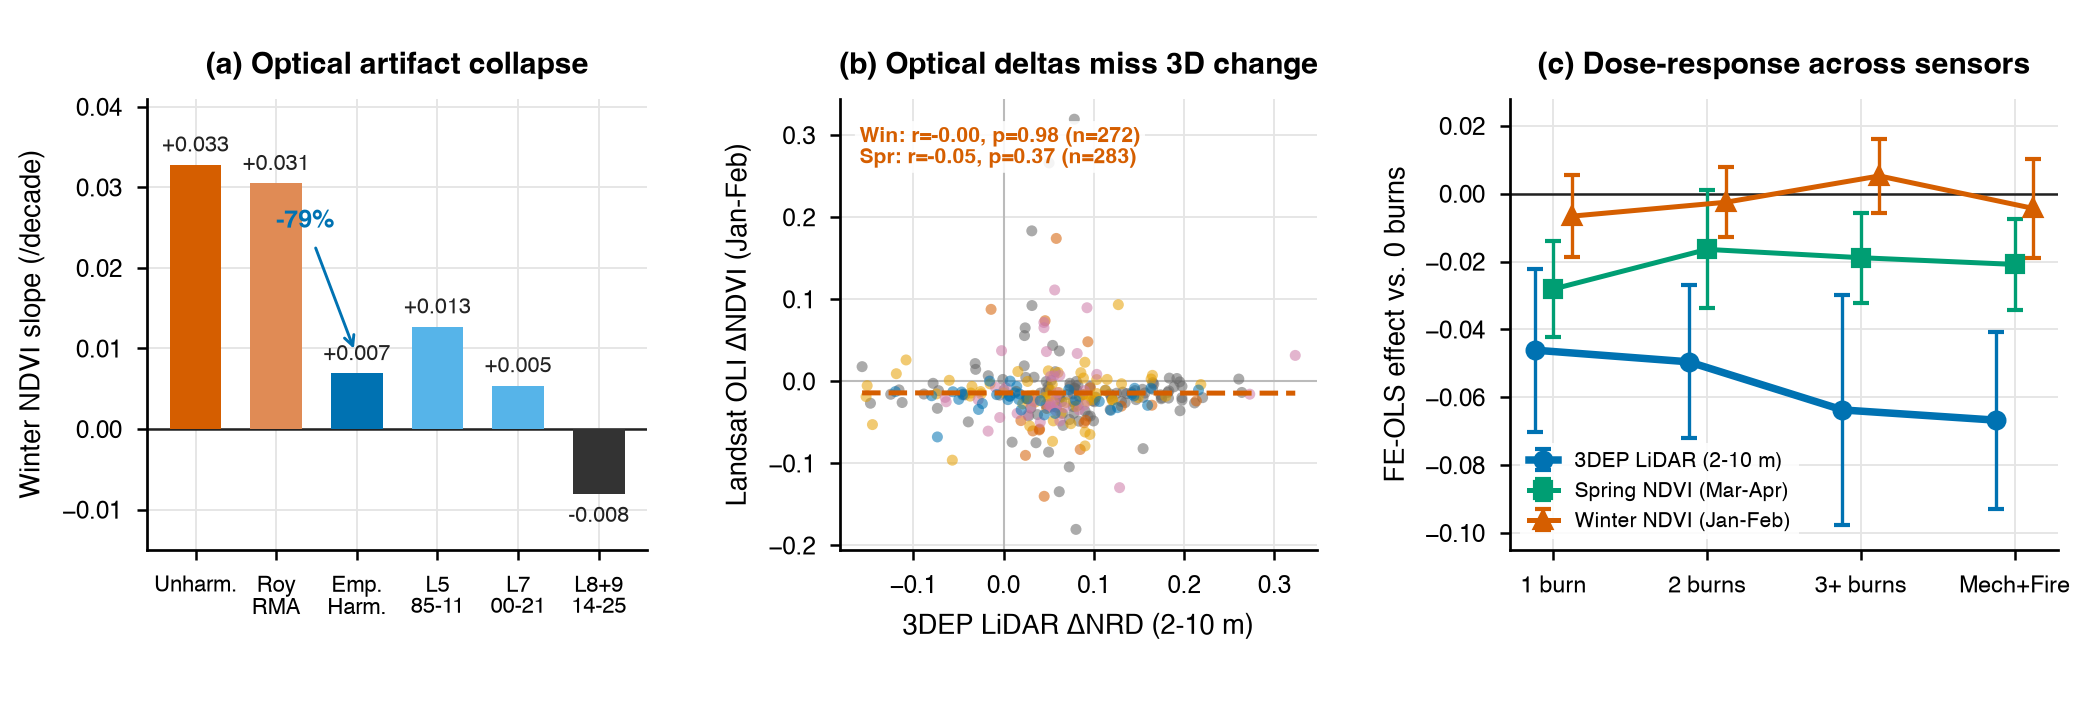

In [2]:
D = load("data/diagnostic_optical.json")
R = load("data/region_metrics.json")

print("=== Regional Pure-Deciduous Inter-Sensor Overlaps ===")
display(pd.DataFrame(D["regional_deciduous_sensor_overlaps"]).T)

print("\n=== Regional Plateau-Top (>=430 m) Trends (/decade) ===")
display(pd.Series(R["trends"]).rename("slope_per_decade").to_frame())

show("paper/figures/fig1_optical_illusion_vs_lidar.png")

## 2. Residual Landsat 5 (1985-2011) Attribution & Sewanee Burn-Cohort Persistence

In [3]:
l5d = D["l5_residual_attribution"]
print("=== Stand-Age & Forest-Type Cohorts (Annual NLCD 1985 -> 2001 -> 2021) ===")
display(pd.DataFrame(l5d["cohorts"]).T)

print("\n=== Spectral Index Contrast on Old Deciduous (1985-2021) Jan-Feb ===")
display(pd.DataFrame(l5d["indices_old_decid"]).T)

print("\n=== Sewanee Burn-Cohort Persistence (Plateau-Top >=530 m Pure Deciduous) ===")
display(pd.DataFrame(D["sewanee_burn_persistence"]).T)

=== Stand-Age & Forest-Type Cohorts (Annual NLCD 1985 -> 2001 -> 2021) ===


,area_km2,L5_1985_2011_JF,L5_1985_2011_DM,L7_2000_2021_JF,L89_2014_2025_JF
old_deciduous_1985_2021,3197.4,0.0134,0.0116,0.0051,-0.0081
regrown_deciduous_1985_2001,11.1,0.0203,0.0180,0.0239,-0.0068
pure_deciduous_2001_2021,3267.6,0.0127,0.0109,0.0054,-0.0081
old_evergreen_1985_2021,53.5,0.0338,0.0340,-0.0019,-0.0235
regrown_evergreen_1985_2001,8.9,0.0871,0.0875,0.0090,-0.0033



=== Spectral Index Contrast on Old Deciduous (1985-2021) Jan-Feb ===


,L5_1985_2011_JF,L89_2014_2025_JF
NDVI,0.0134,-0.0081
NBR,-0.0125,-0.0426
NDMI,-0.0162,-0.0521



=== Sewanee Burn-Cohort Persistence (Plateau-Top >=530 m Pure Deciduous) ===


,area_ha,oli_2014_jf,oli_2022_25_jf,delta_oli,s2_2022_25_jf
control_never_burned,2085.1,0.4398,0.4517,0.0119,0.4121
burned_2013_2018_only,2.6,0.4026,0.4396,0.0370,0.4039
burned_2019_2021_only,45.1,0.4370,0.4432,0.0062,0.4013
burned_2022_2025_only,77.0,0.4466,0.4409,-0.0057,0.3975
burned_2plus_times,160.3,0.4515,0.4523,0.0008,0.4112


## 3. Bug-Fixed Regional Forest Cover, Gross Loss (km^2/yr), and 8 Protected Areas

Regional window: 16,286 km^2 | Plateau top (>=430 m): 6,847 km^2
Annual NLCD forest (km^2): {'1985': 5616.5, '2001': 5135.4, '2021': 5164.0, '2024': 5185.3}
Hansen gross loss 2001-2025: 1,129.1 km^2 (20.75% of standing forest)
NLCD net change 2001->2024: +49.9 km^2 (+0.97%)
Sum of annual loss_by_year_km2 = 1129.1 km^2 (matches loss_km2 = 1129.1 km^2)


,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
km2_lost_per_yr,97.61,68.14,46.99,97.78,80.05,48.24,55.76,93.45,28.66,41.67,...,38.77,46.91,31.83,33.24,28.43,25.11,26.02,14.66,19.19,19.36


,total_ha,pct_plateau,nlcd_pct_deciduous,nlcd_pct_evergreen,unharm_dec_mar_decade,harm_jan_feb_decid_decade,l5_jan_feb_decid_decade,l7_jan_feb_decid_decade,l89_jan_feb_decid_decade,mtbs_fire_count
Prentice Cooper State Forest,10008.9,75.4,93.4,0.5,0.0245,-0.002,0.004,-0.0068,-0.0213,2
North Chickamauga Creek Gorge Designated,2884.9,80.7,61.3,5.9,0.032,0.0016,0.0079,-0.0101,-0.0079,2
Sewanee Domain,5189.9,83.4,97.8,0.1,0.0295,0.0033,0.0116,0.007,-0.008,0
Franklin State Forest,3563.8,83.2,95.1,0.8,0.0302,0.0039,0.0103,0.0014,-0.0035,0
Savage Gulf Designated,6895.7,81.3,70.8,4.6,0.0346,0.008,0.015,0.0037,-0.0117,1
Catoosa,32048.2,82.9,76.1,0.6,0.0319,0.008,0.0053,0.0076,0.0009,2
Fall Creek Falls State Park,10282.4,81.5,69.7,7.3,0.0376,0.0099,0.0209,0.0038,-0.0072,0
Bridgestone/Firestone,4915.3,68.8,77.1,5.3,0.0374,0.0135,0.0221,0.0057,-0.0096,0


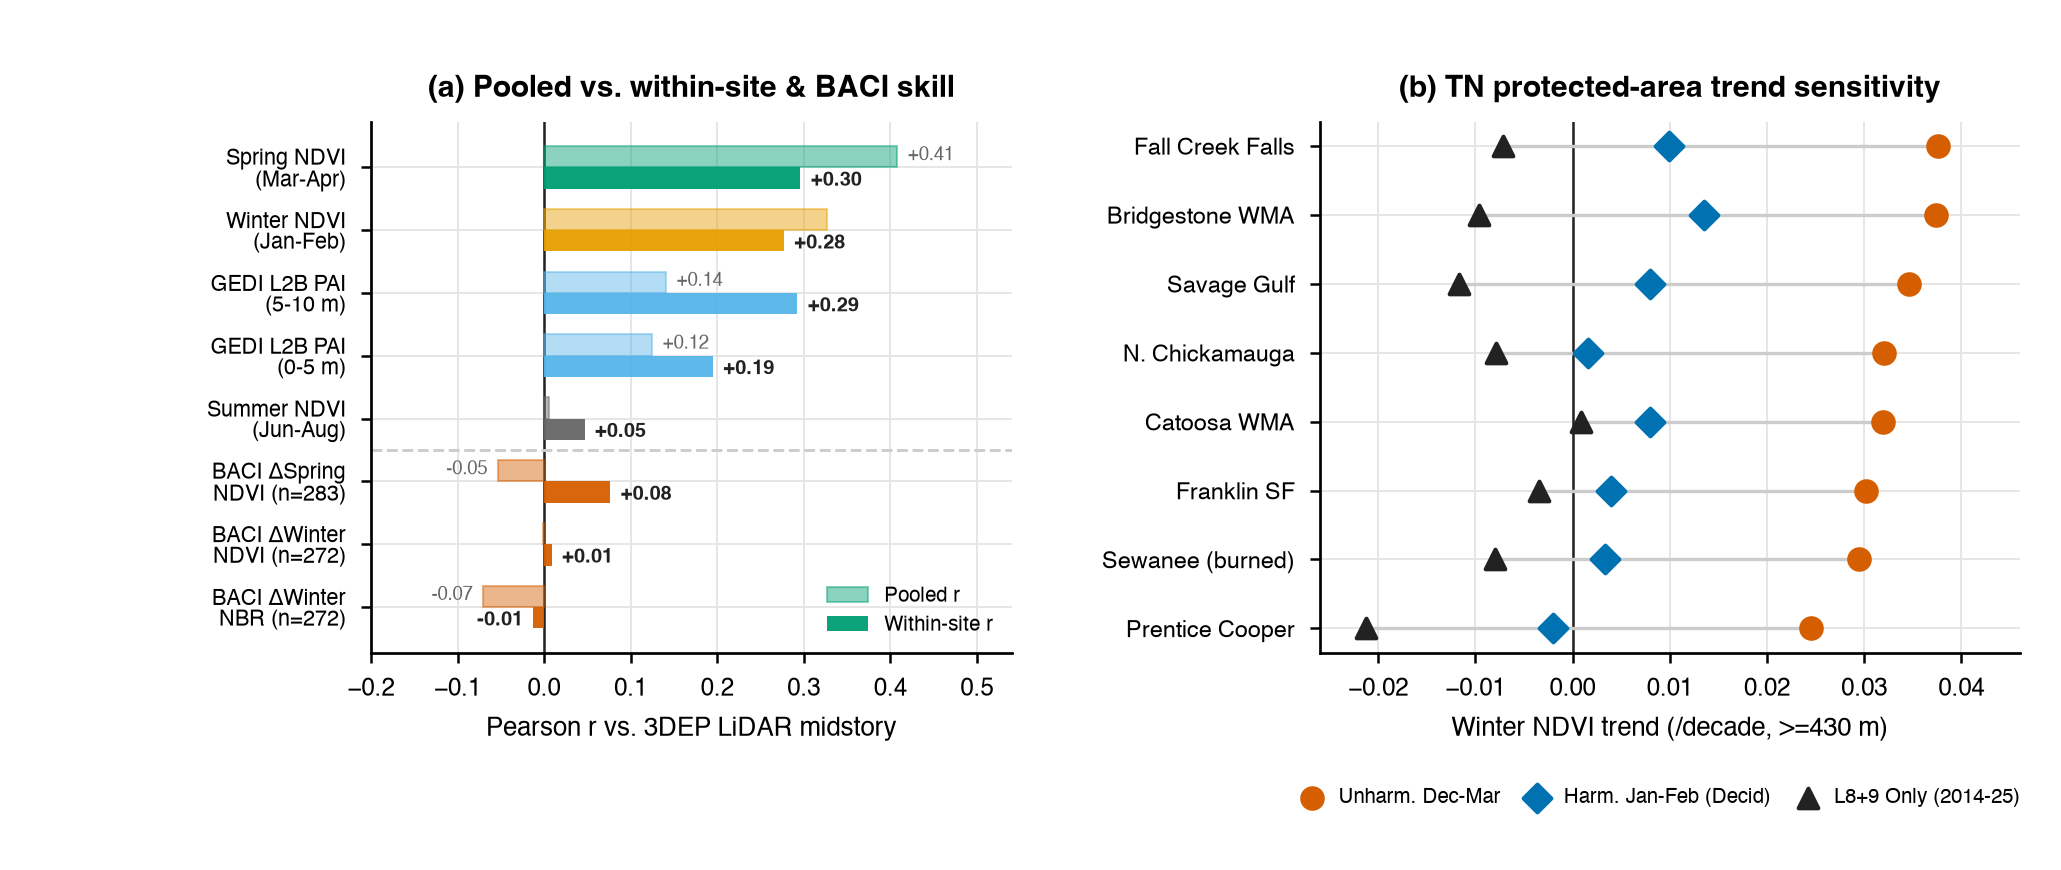

In [4]:
print(f"Regional window: {R['region_km2']:,} km^2 | Plateau top (>=430 m): {R['plateau_km2']:,} km^2")
print(f"Annual NLCD forest (km^2): {R['annual_nlcd_forest_km2']}")
print(f"Hansen gross loss 2001-2025: {R['loss_km2']:,.1f} km^2 ({R['pct_loss']}% of standing forest)")
print(f"NLCD net change 2001->2024: {R['nlcd_net_2001_2024_km2']:+.1f} km^2 ({R['nlcd_net_2001_2024_pct']:+.2f}%)")

# Fixed km^2/yr table (explicitly using loss_by_year_km2 = loss_by_year_ha / 100)
s_km2 = pd.Series({int(k): v for k, v in R["loss_by_year_km2"].items()}).sort_index()
print(f"Sum of annual loss_by_year_km2 = {s_km2.sum():.1f} km^2 (matches loss_km2 = {R['loss_km2']:.1f} km^2)")
display(s_km2.rename("km2_lost_per_yr").to_frame().T)

A = load("data/area_metrics.json")
cols = ["total_ha", "pct_plateau", "nlcd_pct_deciduous", "nlcd_pct_evergreen",
        "unharm_dec_mar_decade", "harm_jan_feb_decid_decade",
        "l5_jan_feb_decid_decade", "l7_jan_feb_decid_decade", "l89_jan_feb_decid_decade", "mtbs_fire_count"]
display(pd.DataFrame(A).T[cols].sort_values("harm_jan_feb_decid_decade"))
show("paper/figures/fig4_sensor_comparison_and_tn_reversal.png")